In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from scipy import sparse

DATA = Path("../data/processed")
RESULTS = Path("../results/phase0")

In [2]:
k562 = sc.read_h5ad(
    DATA / "replogle22k562.h5ad",
    backed="r",
)

rpe1 = sc.read_h5ad(
    DATA / "replogle22rpe1.h5ad",
    backed="r",
)

print("K562:", k562.shape)
print("RPE1:", rpe1.shape)

K562: (308646, 8563)
RPE1: (240774, 8749)


In [3]:
rpe1_gene_set = set(rpe1.var_names)

shared_expression_genes = [
    gene
    for gene in k562.var_names
    if gene in rpe1_gene_set
]

print(
    "Shared expression genes:",
    len(shared_expression_genes)
)

Shared expression genes: 7226


In [4]:
fitness = pd.read_csv(
    RESULTS / "k562_gene_fitness.csv"
)

pilot_targets = fitness["gene"].astype(str).tolist()

print("Pilot targets:", len(pilot_targets))
print("Unique targets:", len(set(pilot_targets)))

Pilot targets: 1641
Unique targets: 1641


In [5]:
available_perturbations = set(
    k562.obs["perturbation"].astype(str)
)

missing = sorted(
    set(pilot_targets)
    - available_perturbations
)

print("Missing pilot targets:", len(missing))
print(missing[:20])

Missing pilot targets: 0
[]


In [6]:
pert_counts = (
    k562.obs["perturbation"]
    .astype(str)
    .value_counts()
)

pilot_counts = (
    pert_counts
    .reindex(pilot_targets)
)

print(pilot_counts.describe())

print("\nLowest cell counts:")
print(pilot_counts.sort_values().head(20))

count    1641.000000
mean      152.993297
std        96.393936
min        30.000000
25%        89.000000
50%       130.000000
75%       187.000000
max       992.000000
Name: count, dtype: float64

Lowest cell counts:
perturbation
ISY1         30
RPL7L1       30
TUBGCP3      30
PSMB3        31
ARID3A       31
HIST2H2BE    31
OGT          31
SMARCE1      31
DNAJC17      31
THOC5        32
RNF4         32
EXOC7        32
TBC1D3       32
PLK4         32
EEF1B2       32
OR1E2        32
ZC3H18       32
CUL7         33
HAUS6        33
HAMP         33
Name: count, dtype: int64


In [10]:
groups = ["control"] + pilot_targets

group_to_idx = {
    group: i
    for i, group in enumerate(groups)
}

n_groups = len(groups)
n_features = len(shared_expression_genes)

expression_sums = np.zeros(
    (n_groups, n_features),
    dtype=np.float64,
)

cell_counts = np.zeros(
    n_groups,
    dtype=np.int64,
)

labels = (
    k562.obs["perturbation"]
    .astype(str)
    .to_numpy()
)

shared_gene_idx = k562.var_names.get_indexer(
    shared_expression_genes
)

assert np.all(shared_gene_idx >= 0)

chunk_size = 5000

print("Groups:", n_groups)
print("RNA features:", n_features)

Groups: 1642
RNA features: 7226


In [9]:
shared_gene_idx = k562.var_names.get_indexer(
    shared_expression_genes
)

print("Number of shared gene indices:", len(shared_gene_idx))
print("Missing indices:", (shared_gene_idx < 0).sum())

Number of shared gene indices: 7226
Missing indices: 0


In [11]:
for start in range(0, k562.n_obs, chunk_size):

    end = min(
        start + chunk_size,
        k562.n_obs,
    )

    # 1. Read ONLY a contiguous block of cells from disk.
    X_chunk = k562.X[start:end]

    # 2. Now that the small block is in memory,
    #    restrict it to our 7,226 shared genes.
    X_chunk = X_chunk[:, shared_gene_idx]

    chunk_labels = labels[start:end]

    # Which cells belong to control or one of our 1,641 targets?
    relevant = np.isin(
        chunk_labels,
        groups,
    )

    if not relevant.any():
        continue

    # Restrict the already-loaded chunk to relevant cells.
    X_relevant = X_chunk[relevant]
    relevant_labels = chunk_labels[relevant]

    for group in np.unique(relevant_labels):

        local_mask = relevant_labels == group

        group_idx = group_to_idx[group]

        group_sum = X_relevant[
            local_mask
        ].sum(axis=0)

        expression_sums[group_idx] += (
            np.asarray(group_sum)
            .ravel()
        )

        cell_counts[group_idx] += (
            local_mask.sum()
        )

    if start % 50000 == 0:
        print(
            f"Processed {start:,} / "
            f"{k562.n_obs:,} cells"
        )

Processed 0 / 308,646 cells
Processed 50,000 / 308,646 cells
Processed 100,000 / 308,646 cells
Processed 150,000 / 308,646 cells
Processed 200,000 / 308,646 cells
Processed 250,000 / 308,646 cells
Processed 300,000 / 308,646 cells


In [12]:
print("Groups with zero cells:", (cell_counts == 0).sum())

print("Control cells:", cell_counts[0])

print(
    "Pilot perturbation cell-count range:",
    cell_counts[1:].min(),
    "to",
    cell_counts[1:].max(),
)

print(
    "Median cells:",
    np.median(cell_counts[1:])
)

Groups with zero cells: 0
Control cells: 10691
Pilot perturbation cell-count range: 30 to 992
Median cells: 130.0


In [13]:
mean_expression = (
    expression_sums
    /
    cell_counts[:, None]
)

print("Mean-expression matrix:", mean_expression.shape)

Mean-expression matrix: (1642, 7226)


In [14]:
control_profile = mean_expression[0]

perturbed_profiles = mean_expression[1:]

response_matrix = (
    perturbed_profiles
    - control_profile
)

print("Response matrix shape:", response_matrix.shape)

Response matrix shape: (1641, 7226)


In [15]:
print(
    "NaN values:",
    np.isnan(response_matrix).sum()
)

print(
    "Infinite values:",
    np.isinf(response_matrix).sum()
)

print(
    "Mean absolute response:",
    np.abs(response_matrix).mean()
)

print(
    "Minimum cells:",
    cell_counts[1:].min()
)

print(
    "Median cells:",
    np.median(cell_counts[1:])
)

print(
    "Maximum cells:",
    cell_counts[1:].max()
)

print(
    "Control cells:",
    cell_counts[0]
)

NaN values: 0
Infinite values: 0
Mean absolute response: 0.03653514180228147
Minimum cells: 30
Median cells: 130.0
Maximum cells: 992
Control cells: 10691


In [16]:
response_magnitude = np.mean(
    np.abs(response_matrix),
    axis=1
)

qc = pd.DataFrame({
    "gene": pilot_targets,
    "n_cells": cell_counts[1:],
    "response_magnitude": response_magnitude,
})

qc.describe()

,n_cells,response_magnitude
count,1641.000000,1641.000000
mean,152.993297,0.036535
std,96.393936,0.014931
min,30.000000,0.012711
25%,89.000000,0.025424
50%,130.000000,0.032542
75%,187.000000,0.044481
max,992.000000,0.124330


In [17]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    qc["n_cells"],
    qc["response_magnitude"]
)

print(f"Spearman rho: {rho:.3f}")
print(f"p-value: {p:.3e}")

Spearman rho: -0.381
p-value: 6.202e-58


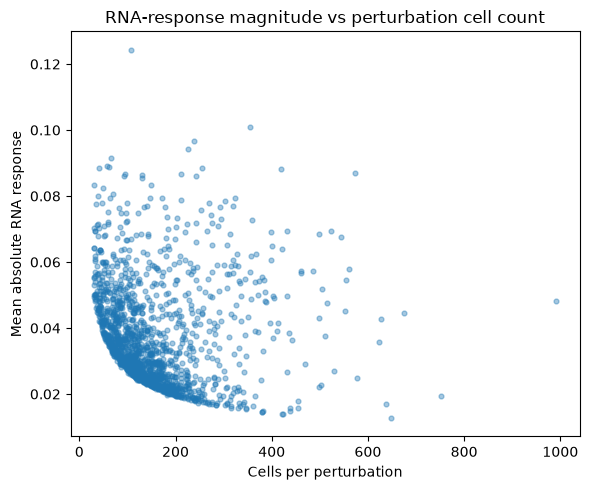

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.scatter(
    qc["n_cells"],
    qc["response_magnitude"],
    s=12,
    alpha=0.4,
)

plt.xlabel("Cells per perturbation")
plt.ylabel("Mean absolute RNA response")
plt.title("RNA-response magnitude vs perturbation cell count")

plt.tight_layout()
plt.show()

In [19]:
fitness_by_gene = (
    fitness
    .set_index("gene")
    .loc[pilot_targets]
)

y = fitness_by_gene["k562_gamma"].to_numpy()

print("Fitness vector shape:", y.shape)
print("RNA rows:", response_matrix.shape[0])

assert len(y) == response_matrix.shape[0]

Fitness vector shape: (1641,)
RNA rows: 1641


In [20]:
rho_cells_fitness, p_cells_fitness = spearmanr(
    cell_counts[1:],
    y
)

print(
    f"Cell count vs fitness rho: "
    f"{rho_cells_fitness:.3f}"
)

print(
    f"p-value: "
    f"{p_cells_fitness:.3e}"
)

Cell count vs fitness rho: -0.071
p-value: 3.880e-03


In [21]:
rho_mag_fitness, p_mag_fitness = spearmanr(
    response_magnitude,
    y
)

print(
    f"RNA magnitude vs fitness rho: "
    f"{rho_mag_fitness:.3f}"
)

print(
    f"p-value: "
    f"{p_mag_fitness:.3e}"
)

RNA magnitude vs fitness rho: -0.543
p-value: 1.255e-126


In [22]:
np.savez_compressed(
    RESULTS / "k562_measured_responses.npz",
    X=response_matrix.astype(np.float32),
    targets=np.array(pilot_targets),
    genes=np.array(shared_expression_genes),
)

qc.to_csv(
    RESULTS / "k562_response_metadata.csv",
    index=False,
)

In [23]:
thresholds = [30, 50, 75, 100, 150]

rows = []

for threshold in thresholds:

    mask = qc["n_cells"].to_numpy() >= threshold

    rho_mag, p_mag = spearmanr(
        response_magnitude[mask],
        y[mask],
    )

    rho_cells, p_cells = spearmanr(
        qc.loc[mask, "n_cells"],
        response_magnitude[mask],
    )

    rows.append({
        "min_cells": threshold,
        "n_perturbations": mask.sum(),
        "rna_magnitude_vs_fitness_rho": rho_mag,
        "rna_magnitude_vs_fitness_p": p_mag,
        "cell_count_vs_rna_magnitude_rho": rho_cells,
    })

sensitivity = pd.DataFrame(rows)

display(sensitivity)

,min_cells,n_perturbations,rna_magnitude_vs_fitness_rho,rna_magnitude_vs_fitness_p,cell_count_vs_rna_magnitude_rho
0,30,1641,-0.543233,1.254642e-126,-0.381310
1,50,1545,-0.575644,4.786045e-137,-0.317632
2,75,1367,-0.610841,1.326883e-140,-0.228851
3,100,1145,-0.630919,3.866667e-128,-0.112999
4,150,669,-0.668968,5.327457e-88,0.100777


In [24]:
from sklearn.linear_model import LinearRegression

log_cells = np.log1p(
    qc["n_cells"].to_numpy()
).reshape(-1, 1)

magnitude_model = LinearRegression()

magnitude_model.fit(
    log_cells,
    response_magnitude,
)

expected_magnitude_from_cells = (
    magnitude_model.predict(log_cells)
)

residual_magnitude = (
    response_magnitude
    - expected_magnitude_from_cells
)

In [25]:
rho_resid, p_resid = spearmanr(
    residual_magnitude,
    y,
)

print(
    f"Cell-count-adjusted RNA magnitude vs fitness rho: "
    f"{rho_resid:.3f}"
)

print(
    f"p-value: {p_resid:.3e}"
)

Cell-count-adjusted RNA magnitude vs fitness rho: -0.623
p-value: 6.066e-177
